# Exercice 1 : Le perceptron

**Objectif : résoudre une classification binaire (la porte logique AND) avec un neuronne et la descente de gradient. Tu l'as déja fait en direct tout en haut de la page ; voici le code NumPy. Il utilise l'entropie croisée, dont le gradient se simplifie en ŷ - y.**

In [2]:
import numpy as np

X = np.array([[0,0], [0,1], [1,0], [1,1]])
y = np.array([0, 0, 0, 1])                     # AND
np.random.seed(42)
w = np.random.randn(2)
b = np.random.randn()

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def predict(X, w, b):
    return sigmoid(X @ w + b)

def bce(y, p, eps=1e-12):                   # entropie croisée binaire
    return -np.mean(y * np.log(p + eps) + (1 - y) * np.log(1 - p + eps))

lr, epochs = 0.5, 2000
for i in range(epochs):
    p = predict(X, w, b)
    dz = p - y                              # gradient de l'entropie croisée
    w -= lr * (X.T @ dz) / len(X)
    b -= lr * dz.mean()
    if i % 200 == 0:
        print(f"Epoch {i}, Loss: {bce(y, p):.4f}")

print("Predictions :", predict(X, w, b).round(3))

Epoch 0, Loss: 0.9452
Epoch 200, Loss: 0.1445
Epoch 400, Loss: 0.0819
Epoch 600, Loss: 0.0567
Epoch 800, Loss: 0.0431
Epoch 1000, Loss: 0.0347
Epoch 1200, Loss: 0.0290
Epoch 1400, Loss: 0.0249
Epoch 1600, Loss: 0.0218
Epoch 1800, Loss: 0.0194
Predictions : [0.    0.02  0.02  0.972]


***A toi : refais l'exercice avec la porte NOR.***

In [3]:
import numpy as np

X = np.array([[0,0], [0,1], [1,0], [1,1]])
y = np.array([1, 0, 0, 0])                  # NOR : np.array([1,0,0,0])

np.random.seed(42)
w = np.random.randn(2)
b = np.random.randn()

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def predict(X, w, b):
    return sigmoid(X @ w + b)

def bce(y, p, eps=1e-12):                   # entropie croisée binaire
    return -np.mean(y * np.log(p + eps) + (1 - y) * np.log(1 - p + eps))

lr, epochs = 0.5, 2000
for i in range(epochs):
    p = predict(X, w, b)
    dz = p - y                              # gradient de l'entropie croisée
    w -= lr * (X.T @ dz) / len(X)
    b -= lr * dz.mean()
    if i % 200 == 0:
        print(f"Epoch {i}, Loss: {bce(y, p):.4f}")

print("Predictions :", predict(X, w, b).round(3))

Epoch 0, Loss: 1.0348
Epoch 200, Loss: 0.0886
Epoch 400, Loss: 0.0467
Epoch 600, Loss: 0.0314
Epoch 800, Loss: 0.0235
Epoch 1000, Loss: 0.0188
Epoch 1200, Loss: 0.0156
Epoch 1400, Loss: 0.0133
Epoch 1600, Loss: 0.0116
Epoch 1800, Loss: 0.0103
Predictions : [0.98  0.008 0.008 0.   ]


# Exercice 2 : Iris avec un MLP

**Objectif : classer les fleurs Iris en 3 classes à partir de 4 mesures. Retiens l'odre des opérations : on sépare d'abord, puis on ajuste le StandardScaler sur le train seulement. Sinon la moyenne et l'écart-type du jeu test influencent l'entraînement (fuite de données)**

In [4]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Dense 

X, y = load_iris(return_X_y=True)               # 4 features, classes 0, 1, 2

# 1. on sépare d'abord
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# 2. on ajuste le scaler sur le train uniquement
scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

model = Sequential([
    Input(shape=(4,)),
    Dense(8, activation="relu"),
    Dense(3, activation="softmax"),
])
model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",    # y_train contient 0, 1, 2 (pas de one hot)
              metrics=["accuracy"])
model.summary()

hystory = model.fit(X_train, y_train, epochs=300, batch_size=16, validation_split=0.1, verbose=0)

loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"Test Accuracy: {accuracy * 100:.2f}%")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 8)              │            40 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 67 (268.00 B)

 Trainable params: 67 (268.00 B)

 Non-trainable params: 0 (0.00 B)

Test Accuracy: 93.33%


*Le test donne environ 90% de bonnes réponses. Avec 100 époques seulement, le réseau n'a pas fini d'apprendre : regarde les courbes history.history pour le constater*

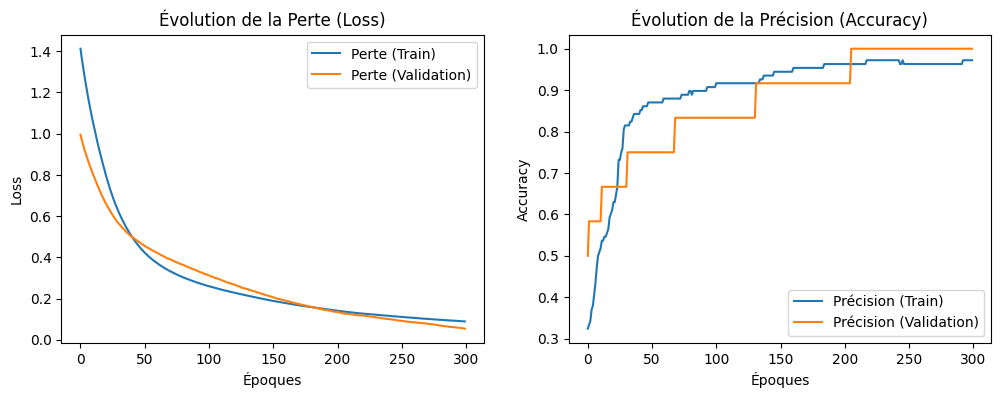

In [5]:
import matplotlib.pyplot as plt

# 1. Récupérer l'historique des métriques stockées pendant l'entraînement
hist = hystory.history

# 2. Tracer la perte (Loss) pour l'entraînement et la validation
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(hist['loss'], label="Perte (Train)")
plt.plot(hist['val_loss'], label="Perte (Validation)")
plt.title("Évolution de la Perte (Loss)")
plt.xlabel("Époques")
plt.ylabel("Loss")
plt.legend()

# 3. Tracer la précision (Accuracy) pour l'entraînement et la validation
plt.subplot(1, 2, 2)
plt.plot(hist['accuracy'], label="Précision (Train)")
plt.plot(hist['val_accuracy'], label="Précision (Validation)")
plt.title("Évolution de la Précision (Accuracy)")
plt.xlabel("Époques")
plt.ylabel("Accuracy")
plt.legend()

plt.show()


# Exercice 2, suite : Titanic

**Objectif : prédire la survie d'un passager (classification binaire). Etapes, dans l'ordre :**
1. Choisir les colonnes pertinentes (features).
2. Séparer les données en train et test.
3. Gérer les valeurs manquantes, avec les statistiques du train.
4. Encoder les colonnes catégorielles.
5. Normaliser les colonnes numériques.
6. Convertir en tableaux numpy.
7. Vérifier les dimensions.

Toutes les statistiques (médiane de l'âge, mode de l'embarquement, moyenne et écart-type du scaler) se calculent sur le train. stratify garde la même proportion de survivants dans les deux jeux, et l'arrêt anticipé interrompt l'entraînement quand la validation ne progresse plus.

In [6]:
import pandas as pd 
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Dense 
from tensorflow.keras.callbacks import EarlyStopping

titanic = sns.load_dataset("titanic")
features = ["pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]
X, y = titanic[features], titanic["survived"].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# 1. valeurs manquantes : on utilise les statistiques du train
fill = {"age": X_train["age"].median(), "embarked": X_train["embarked"].mode()[0]}
X_train = X_train.fillna(fill)
X_test = X_test.fillna(fill)

# 2. variables catégorielles (mêmes colonnes pour train et test)
cat = ["sex", "embarked", "pclass"]
X_train = pd.get_dummies(X_train, columns=cat, drop_first=True)
X_test = pd.get_dummies(X_test, columns=cat, drop_first=True)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

# 3. normalisation des colonnes numériques (fit sur le train)
num = ["age", "fare"]
scaler = StandardScaler().fit(X_train[num])
X_train[num] = scaler.transform(X_train[num])
X_test[num] = scaler.transform(X_test[num])

# 4. conversion en tableau numpy et vérification des dimensions
X_train = X_train.values.astype("float32")
X_test = X_test.values.astype("float32")
print("Shape X_train:", X_train.shape, "| Shape X_test:", X_test.shape)

model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(16, activation="relu"),
    Dense(1, activation="sigmoid"),
])
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

early = EarlyStopping(patience=10, restore_best_weights=True)
history = model.fit(X_train, y_train, epochs=100, batch_size=32, validation_split=0.1, callbacks=[early], verbose=0)

pred = (model.predict(X_test) > 0.5).astype(int).ravel()
print(classification_report(y_test, pred))

Shape X_train: (712, 9) | Shape X_test: (179, 9)
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
              precision    recall  f1-score   support

           0       0.79      0.93      0.85       110
           1       0.84      0.61      0.71        69

    accuracy                           0.80       179
   macro avg       0.82      0.77      0.78       179
weighted avg       0.81      0.80      0.80       179



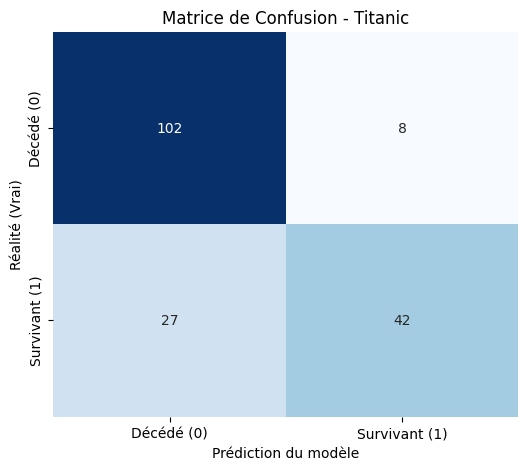

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 1. Calculer la matrice de confusion
cm = confusion_matrix(y_test, pred)

# 2. L'afficher joliment sous forme de graphique (heatmap)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Décédé (0)", "Survivant (1)"],
            yticklabels=["Décédé (0)", "Survivant (1)"])

plt.xlabel("Prédiction du modèle")
plt.ylabel("Réalité (Vrai)")
plt.title("Matrice de Confusion - Titanic")
plt.show()

*Regarde ensuite history.history : si la perte de validation remonte alors que celle d'entraînement continuer de baisser, c'est du sur-apprentissage. Compare 16 neuronnes cachés avec 4 puis avec 64.*

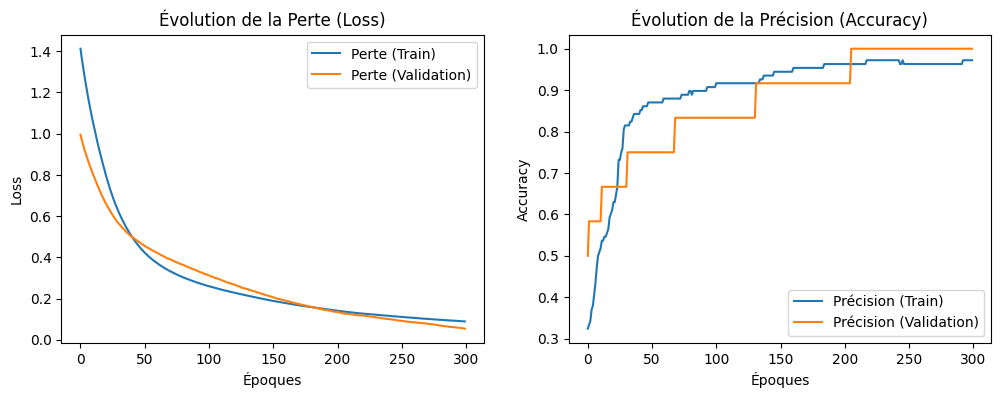

In [8]:
import matplotlib.pyplot as plt

# 1. Récupérer l'historique des métriques stockées pendant l'entraînement
hist = hystory.history

# 2. Tracer la perte (Loss) pour l'entraînement et la validation
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(hist['loss'], label="Perte (Train)")
plt.plot(hist['val_loss'], label="Perte (Validation)")
plt.title("Évolution de la Perte (Loss)")
plt.xlabel("Époques")
plt.ylabel("Loss")
plt.legend()

# 3. Tracer la précision (Accuracy) pour l'entraînement et la validation
plt.subplot(1, 2, 2)
plt.plot(hist['accuracy'], label="Précision (Train)")
plt.plot(hist['val_accuracy'], label="Précision (Validation)")
plt.title("Évolution de la Précision (Accuracy)")
plt.xlabel("Époques")
plt.ylabel("Accuracy")
plt.legend()

plt.show()


In [9]:
# Test avec 3 tailles différentes de couches cachées
for n_neurons in [4, 16, 64]:
  print(f"\n--- Modèle avec {n_neurons} neurones ---")

  # 1. Création du modèle
  model = Sequential([
      Input(shape=(X_train.shape[1],)),
      Dense(n_neurons, activation="relu"),
      Dense(1, activation="sigmoid"),
  ])
  model.compile(
      optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"]
  )

  # 2. Entraînement (sans EarlyStopping pour bien voir toute l'évolution sur 100 époques)
  history = model.fit(
      X_train, y_train, epochs=100, batch_size=32, validation_split=0.1, verbose=0
  )

  # 3. Récupération des pertes finales
  final_train_loss = history.history["loss"][-1]
  print(f"Perte (Loss) Entraînement : {final_train_loss:.4f}")


--- Modèle avec 4 neurones ---
Perte (Loss) Entraînement : 0.4359

--- Modèle avec 16 neurones ---
Perte (Loss) Entraînement : 0.3900

--- Modèle avec 64 neurones ---
Perte (Loss) Entraînement : 0.3541


Plus le modèle possède de neurones, plus il a de capacité pour apprendre et réduire son erreur d'entraînement. Cependant, un nombre trop élevé de neurones augmente le risque de surapprentissage sur de nouvelles données.

# Exercice 3 : un CNN sur MNIST

**Objectif : classer des images de chiffre manuscrits (0 à 9) avec un réseau convolutif. Le réseau compte 130 890 paramètres, et la dernière couche convolutive sort 3 x 3 x 64 = 576 valeurs, que Flatten met à plat.
La validation est prélevée dans le train, pour que le test reste inconnu jusqu'à l'évaluation finale.**

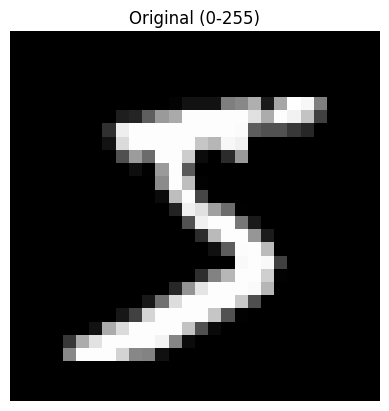

Formes finales : (60000, 28, 28, 1) (10000, 28, 28, 1)


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 3, 3, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 130,890 (511.29 KB)

 Trainable params: 130,890 (511.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 17s 17ms/step - accuracy: 0.9193 - loss: 0.2630 - val_accuracy: 0.9873 - val_loss: 0.0431
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 17s 20ms/step - accuracy: 0.9788 - loss: 0.0744 - val_accuracy: 0.9902 - val_loss: 0.0334
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 21s 25ms/step - accuracy: 0.9851 - loss: 0.0515 - val_accuracy: 0.9912 - val_loss: 0.0296
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 17s 20ms/step - accuracy: 0.9876 - loss: 0.0428 - val_accuracy: 0.9917 - val_loss: 0.0274
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 17s 21ms/step - accuracy: 0.9898 - loss: 0.0352 - val_accuracy: 0.9915 - val_loss: 0.0313
313/313 - 1s - 5ms/step - accuracy: 0.9922 - loss: 0.0244

Précision sur le test : 99.22%
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


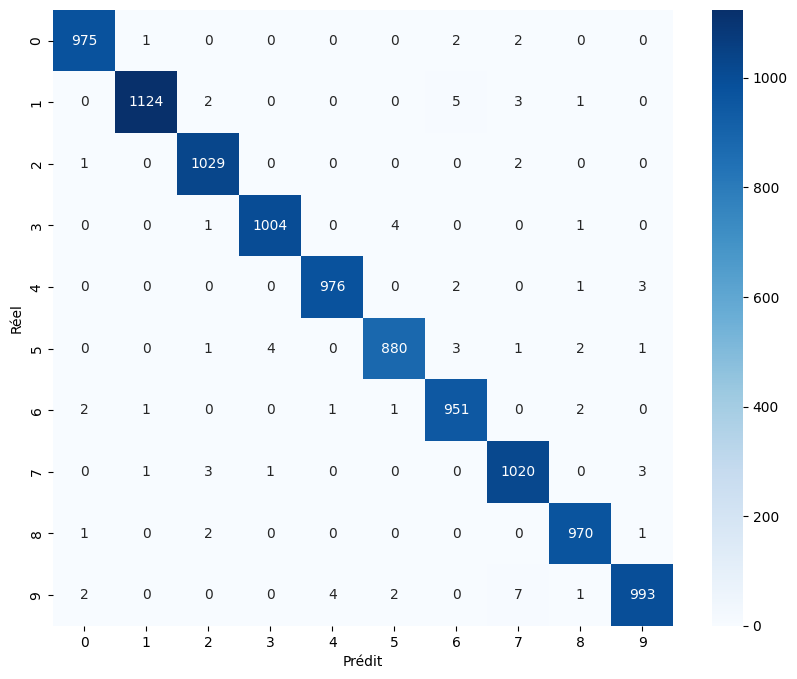

              precision    recall  f1-score   support

           0       0.99      0.99      0.99       980
           1       1.00      0.99      0.99      1135
           2       0.99      1.00      0.99      1032
           3       1.00      0.99      0.99      1010
           4       0.99      0.99      0.99       982
           5       0.99      0.99      0.99       892
           6       0.99      0.99      0.99       958
           7       0.99      0.99      0.99      1028
           8       0.99      1.00      0.99       974
           9       0.99      0.98      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



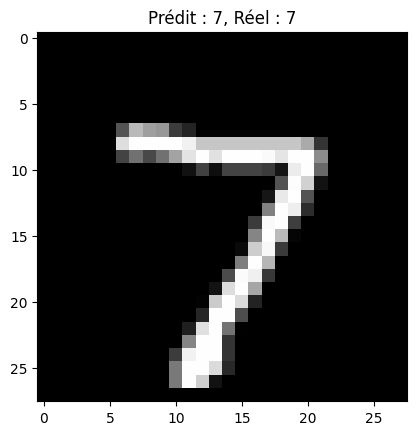

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 
from tensorflow.keras import datasets, layers, models, Input
from sklearn.metrics import confusion_matrix, classification_report

(X_train, y_train), (X_test, y_test) = datasets.mnist.load_data()

# une image brute (valeurs 0 à 255), avant toute transformation
img = X_train[y_train == 5][0]
plt.imshow(img, cmap="gray")
plt.title("Original (0-255)")
plt.axis("off")
plt.show()

# normalisation (0 à 1) puis ajout du canal : (N, 28, 28) --> (N, 28, 28, 1)
X_train = np.expand_dims(X_train.astype("float32") / 255.0, -1)
X_test = np.expand_dims(X_test.astype("float32") / 255.0, -1)
print("Formes finales :", X_train.shape, X_test.shape)

model = models.Sequential([
    Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPool2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPool2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(10, activation="softmax"),
])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

# la validation est prise dans le train : le test reste inconnu jusqu'à l'évaluation finale
history = model.fit(X_train, y_train, epochs=5, batch_size=64, validation_split=0.1)

loss, acc = model.evaluate(X_test, y_test, verbose=2)
print(f"\nPrécision sur le test : {acc * 100:.2F}%")

y_pred = np.argmax(model.predict(X_test), axis=1)

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Prédit")
plt.ylabel("Réel")
plt.show()

print(classification_report(y_test, y_pred))

plt.imshow(X_test[0].squeeze(), cmap="gray")
plt.title(f"Prédit : {y_pred[0]}, Réel : {y_test[0]}")
plt.show()

***A faire :***

***- Prépare une présentation qui explique le fonctionnement d'un CNN et le rôle de chaque couche :***

*Conv2D, MaxPooling2D, Flatten, Dense, Dropout.*

***- Explique le code ci-dessus étape par étape : prétraitement, architecture, entraînement, évaluation.***

##### 1. Le Prétraitement (Préparation)

***Chargement :*** On télécharge la base de données MNIST (60 000 images de chiffres écrits à la main pour l'apprentissage, 10 000 pour les tests).

***Normalisation :*** On divise les pixels par 255 pour que leurs valeurs passent de 0-255 à 0-1, ce qui aide grandement l'ordinateur à apprendre.

***Format :*** On ajoute une dimension pour indiquer qu'il s'agit d'images en noir et blanc.

##### 2. L'Architecture (Le Modèle CNN)

*On construit un réseau de neurones en couches successives :*

***Détection visuelle (Conv2D + MaxPool2D) :*** Des filtres parcourent l'image pour repérer les formes (lignes, courbes, boucles) et réduisent l'image pour garder l'essentiel.

***Réflexion (Dense + Dropout) :*** On aplatit l'image et on la fait passer par des neurones classiques. Le Dropout éteint la moitié des neurones au hasard pour empêcher le modèle d'apprendre par cœur.

***Sortie (Dense(10)) :*** Les 10 derniers neurones donnent la probabilité pour chaque chiffre de 0 à 9. Le plus fort l'emporte.

##### 3. L'Entraînement (model.fit)

Le modèle analyse les 60 000 images 5 fois (epochs=5) par paquets de 64 (batch_size=64). À chaque fois, il ajuste ses réglages pour faire de moins en moins d'erreurs.

##### 4. L'Évaluation (model.evaluate et graphiques)

On teste le modèle sur les 10 000 images inconnues pour mesurer sa précision (souvent ~98%).
On utilise une matrice de confusion pour voir s'il confond certains chiffres (ex: un 4 pris pour un 9).
Enfin, on affiche une image avec sa prédiction pour vérifier visuellement le résultat.

# Exercice 4 : un CNN sur Fashion-MNIST

**Objectif : classer des images de vêtements en 10 catégories. Les données ont le même format que MNIST**
**(images de 28 x 28 pixels, 60 000 pour l'entraînement et 10 000 pour le test).**

In [11]:
import tensorflow as tf

(X_train, y_train), (X_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()
print(X_train.shape, y_train.shape)             # (60000, 28, 28) (60000,)

classes = ["T-shirt/top", "Pantalon", "Pull", "Robe", "Manteau",
           "Sandale", "Chemise", "Sneaker", "Sac", "Bottine"]

(60000, 28, 28) (60000,)


A toi : reprends les étapes de l'exercice 3 (normalisation, canal, CNN, entraînement, évaluation, matrice de 
confusion) et repère les classes que le réseau confond le plus.

Formes initiales : (60000, 28, 28) (60000,)


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 3, 3, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 128)            │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 130,890 (511.29 KB)

 Trainable params: 130,890 (511.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 19s 21ms/step - accuracy: 0.7501 - loss: 0.6833 - val_accuracy: 0.8443 - val_loss: 0.4244
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 16s 19ms/step - accuracy: 0.8457 - loss: 0.4310 - val_accuracy: 0.8698 - val_loss: 0.3512
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 17s 20ms/step - accuracy: 0.8714 - loss: 0.3624 - val_accuracy: 0.8757 - val_loss: 0.3311
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 18s 21ms/step - accuracy: 0.8837 - loss: 0.3264 - val_accuracy: 0.8943 - val_loss: 0.2912
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 18s 22ms/step - accuracy: 0.8912 - loss: 0.2993 - val_accuracy: 0.8933 - val_loss: 0.2820
313/313 - 2s - 5ms/step - accuracy: 0.8902 - loss: 0.2978

Précision sur le test : 89.02%
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step


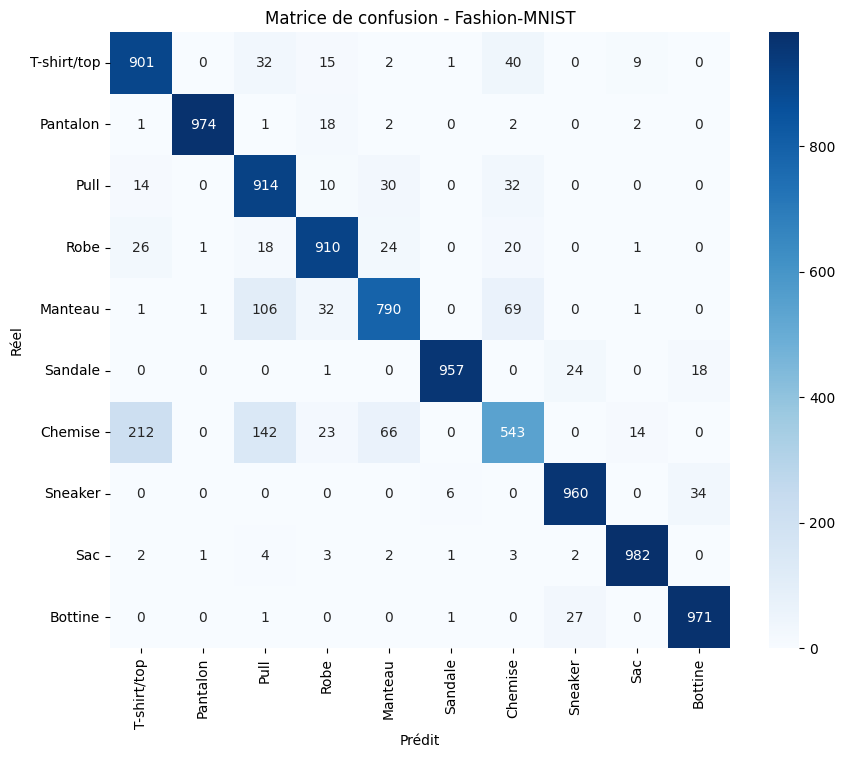

              precision    recall  f1-score   support

 T-shirt/top       0.78      0.90      0.84      1000
    Pantalon       1.00      0.97      0.99      1000
        Pull       0.75      0.91      0.82      1000
        Robe       0.90      0.91      0.90      1000
     Manteau       0.86      0.79      0.82      1000
     Sandale       0.99      0.96      0.97      1000
     Chemise       0.77      0.54      0.64      1000
     Sneaker       0.95      0.96      0.95      1000
         Sac       0.97      0.98      0.98      1000
     Bottine       0.95      0.97      0.96      1000

    accuracy                           0.89     10000
   macro avg       0.89      0.89      0.89     10000
weighted avg       0.89      0.89      0.89     10000



In [12]:
# 1. Chargement des données Fashion-MNIST
(X_train, y_train), (X_test, y_test) = datasets.fashion_mnist.load_data()
print("Formes initiales :", X_train.shape, y_train.shape)

classes = [
    "T-shirt/top",
    "Pantalon",
    "Pull",
    "Robe",
    "Manteau",
    "Sandale",
    "Chemise",
    "Sneaker",
    "Sac",
    "Bottine",
]

# 2. Prétraitement (Normalisation 0-1 + Ajout du canal)
X_train = np.expand_dims(X_train.astype("float32") / 255.0, -1)
X_test = np.expand_dims(X_test.astype("float32") / 255.0, -1)

# 3. Architecture du CNN
model = models.Sequential([
    Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPool2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPool2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(10, activation="softmax"),
])

model.compile(
    optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"]
)
model.summary()

# 4. Entraînement
history = model.fit(
    X_train, y_train, epochs=5, batch_size=64, validation_split=0.1
)

# 5. Évaluation
loss, acc = model.evaluate(X_test, y_test, verbose=2)
print(f"\nPrécision sur le test : {acc * 100:.2F}%")

# 6. Prédictions et Matrice de confusion avec les noms de classes
y_pred = np.argmax(model.predict(X_test), axis=1)

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes,
)
plt.xlabel("Prédit")
plt.ylabel("Réel")
plt.title("Matrice de confusion - Fashion-MNIST")
plt.show()

# Rapport détaillé par classe
print(classification_report(y_test, y_pred, target_names=classes))

# Exercice 5 : un RNN qui génère du texte

**Objectif : prédire le mot suivant à partir des 3 mots précédents, puis écrire un texte mot après mot. Prépare un fichier *textes.txt* (UTF-8) avec un texte par ligne. Les exemples d'entraînement et la génération utilisent le même format : une fenêtre de 3 mots, complétée par des zéros au début si besoin.**

Exemple de texte : Le sport occupe une place importante dans notre vie quotidienne.
X shape: (186, 3), y shape: (186,)
Epoch 1/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.0054 - loss: 6.9049    
Epoch 2/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.0753 - loss: 6.8875 
Epoch 3/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.1183 - loss: 6.8658 
Epoch 4/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.1344 - loss: 6.8342 
Epoch 5/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.1183 - loss: 6.7803 
Epoch 6/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.1129 - loss: 6.6872 
Epoch 7/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.0860 - loss: 6.5292 
Epoch 8/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.0699 - loss: 6.2686 
Epoch 9/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.0645 - loss: 5.8982
Epoch 10/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.0538 - loss: 5.4796
Epoch 11/500
6/6 ━━━━━━━━━━━━━━━━━━━━

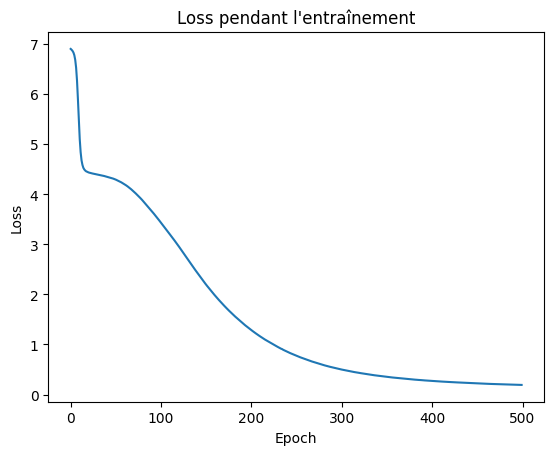

le sport permet également de se faire de nouveaux amis activité importante les se vie apprennent bien


In [13]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.callbacks import EarlyStopping

with open("textes.txt", "r", encoding="utf-8") as f:
    texts = [line.strip() for line in f if line.strip()]
print(f"Exemple de texte : {texts[0]}")

vocab_size = 1000
window_size = 3

tokenizer = Tokenizer(num_words=vocab_size)
tokenizer.fit_on_texts(texts)
sequences = tokenizer.texts_to_sequences(texts)

# exemples d'apprentissage : au plus 3 mots précédents --> mot suivant
X, y = [], []
for seq in sequences:
    for i in range(1, len(seq)):
        X.append(seq[max(0, i - window_size):i])
        y.append(seq[i])
X = pad_sequences(X, maxlen=window_size, padding="pre")
y = np.array(y)
print(f"X shape: {X.shape}, y shape: {y.shape}")

embedding_dim = 16
model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=embedding_dim),
    SimpleRNN(32),
    Dense(vocab_size, activation="softmax"),
])
model.compile(loss="sparse_categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

early_stop = EarlyStopping(monitor="loss", patience=10, restore_best_weights=True)
history = model.fit(X, y, epochs=500, batch_size=32, callbacks=[early_stop])

plt.plot(history.history["loss"])
plt.title("Loss pendant l'entraînement")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

def generate_text(start_text, num_words=50, temperature=0.8):
    text = start_text
    for _ in range(num_words):
        # même format qu'à l'entraînement : les 3 derniers mots seulement
        tokens = tokenizer.texts_to_sequences([text])[0][-window_size:]
        tokens = pad_sequences([tokens], maxlen=window_size, padding="pre")
        probs = model.predict(tokens, verbose=0)[0]

        # tirage au sort pondéré (température < 1 : plus sûr, > 1 : plus varié)
        probs = np.exp(np.log(probs + 1e-9) / temperature)
        probs /= probs.sum()
        index = np.random.choice(len(probs), p=probs)

        word = tokenizer.index_word.get(index)
        if word is not None:
            text += " " + word 
    return text 

print(generate_text("le sport", num_words=50))

*Teste ensuite un LSTM : remplace SimpleRNN(32) par LSTM(64) (import: from tensorflow.keras.layers import LSTM) et compare la loss et le texte obtenu. Change aussi temperature : plus elle est basse, plus le texte se répète.*

Exemple de texte : Le sport occupe une place importante dans notre vie quotidienne.
X shape: (186, 3), y shape: (186,)
Epoch 1/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.0269 - loss: 6.9060    
Epoch 2/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.0699 - loss: 6.8951 
Epoch 3/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.0968 - loss: 6.8823 
Epoch 4/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.1129 - loss: 6.8644 
Epoch 5/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.1075 - loss: 6.8358
Epoch 6/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.1129 - loss: 6.7854
Epoch 7/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.0645 - loss: 6.6945
Epoch 8/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.0538 - loss: 6.5134 
Epoch 9/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.0538 - loss: 6.1823 
Epoch 10/500
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.0538 - loss: 5.6572     
Epoch 11/500
6/6 ━━━━━━━━━━━━━━━━

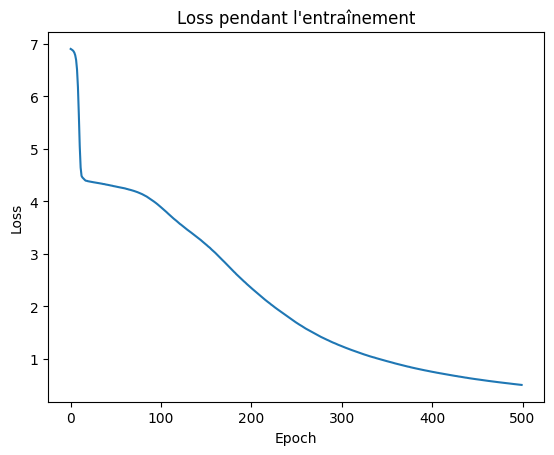

le sport aide à développer la force et l’endurance arbitres la dormir respect sociale équipe force travailler arbitres équipe santé confiance dans dans santé et et garder la la équipe moral la dans vie sociale efforts équipe l’endurance faire les natation prendre apprennent prendre réduire le sport est bénéfique pour la


In [14]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense, LSTM
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.callbacks import EarlyStopping

with open("textes.txt", "r", encoding="utf-8") as f:
    texts = [line.strip() for line in f if line.strip()]
print(f"Exemple de texte : {texts[0]}")

vocab_size = 1000
window_size = 3

tokenizer = Tokenizer(num_words=vocab_size)
tokenizer.fit_on_texts(texts)
sequences = tokenizer.texts_to_sequences(texts)

# exemples d'apprentissage : au plus 3 mots précédents --> mot suivant
X, y = [], []
for seq in sequences:
    for i in range(1, len(seq)):
        X.append(seq[max(0, i - window_size):i])
        y.append(seq[i])
X = pad_sequences(X, maxlen=window_size, padding="pre")
y = np.array(y)
print(f"X shape: {X.shape}, y shape: {y.shape}")

embedding_dim = 16
model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=embedding_dim),
    LSTM(64),
    Dense(vocab_size, activation="softmax"),
])
model.compile(loss="sparse_categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

early_stop = EarlyStopping(monitor="loss", patience=10, restore_best_weights=True)
history = model.fit(X, y, epochs=500, batch_size=32, callbacks=[early_stop])

plt.plot(history.history["loss"])
plt.title("Loss pendant l'entraînement")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

def generate_text(start_text, num_words=50, temperature=0.2):
    text = start_text
    for _ in range(num_words):
        # même format qu'à l'entraînement : les 3 derniers mots seulement
        tokens = tokenizer.texts_to_sequences([text])[0][-window_size:]
        tokens = pad_sequences([tokens], maxlen=window_size, padding="pre")
        probs = model.predict(tokens, verbose=0)[0]

        # tirage au sort pondéré (température < 1 : plus sûr, > 1 : plus varié)
        probs = np.exp(np.log(probs + 1e-9) / temperature)
        probs /= probs.sum()
        index = np.random.choice(len(probs), p=probs)

        word = tokenizer.index_word.get(index)
        if word is not None:
            text += " " + word 
    return text 

print(generate_text("le sport", num_words=50))

## Questions

##### 1. Que fait ***Tokenizer*** et pourquoi est-il nécessaire avant un ***RNN*** ?

***Tokenizer*** va traduire les mots en nombres uniques parce que les réseaux de neuronnes ne comprennent pas les textes. Il est nécessaire avant un ***RNN*** (Réseau de Neurones Récurrent) pour qu'il puisse exploiter les mots sous forme de données mathématiques.

##### 2. Pourquoi utilise-t-on ***pad_sequences***, et que se passerait-il sans lui ?

***pad_sequences*** uniformise la longueur de toutes les phrases en rajoutant des zéros pour former des matrices exigées par le réseau de neurones. Sans ça, TensorFlow renvoit une erreur car il ne peut pas regrouper des séquences de longueurs différentes dans un même lot d'entraînement.

##### 3. Quelle est la différence entre ***vocab_size*** et ***embedding_dim*** ?

***vocab_size*** c'est le nombre total de mots uniques que le modèle connaît et garde en mémoire.

***embedding_dim*** c'est la taille de la carte d'identité numérique d'un mot. On augmentera le nombre pour avoir plus de détails et de nuances sur le sens du mot.

L'un compte les mots et l'autre mesure la description de chaque mot.

##### 4. En quoi consiste une couche ***Embedding***, et pourquoi la place-t-on avant le ***RNN*** ?

La couche ***Embedding*** transforme chaque numéro de mot en une riche description numérique pour que des mots aux sens proches se ressemblent mathématiquement. On la place avant le ***RNN*** car celui-ci a impérativement besoin de ces vecteurs nuancés pour analyser correctement le sens et l'ordre des phrases.

##### 5. Quelle est la différence entre ***SimpleRNN*** et ***LSTM*** ? Dans quel cas préférer un ***LSTM*** ?

Le ***SimpleRNN*** possède une mémoire très limitée qui oublie rapidement le début des longues phrases, tandis que le ***LSTM*** intègre des mécanismes intelligents pour retenir efficacement l'information à long terme. On préfère donc quasi systématiquement le LSTM dès que les textes sont un peu longs ou complexes.

##### 6. Que représente ***window_size = 3*** et comment influence-t-il l'apprentissage ?

***window_size = 3*** signifie que le modèle analyse les données par blocs de 3 éléments consécutifs pour capturer les tendances locales. Cela influence l'apprentissage en limitant le modèle à un contexte immédiat et restreint, nécessitant un ajustement selon la portée de la séquence à observer.

##### 7. Pourquoi utiliser ***sparse_categorical_crossentropy*** dans ce cas précis ?

On utilise ***sparse_categorical_crossentropy*** lorsque les réponses attendues sont de simples chiffres (comme la classe 0, 1 ou 2), ce qui évite d'avoir à modifier et compliquer les données avant de les donner au modèle.

##### 8. Que fait le callback ***EarlyStopping*** et pourquoi est-il utile ici ?

Il surveille l'entraînement du modèle et l'arrête automatiquement dès que les performances cessent de s'améliorer.
Il évite le surapprentissage (overfitting), c'est-à-dire le moment où le modèle commence à "apprendre par cœur" ses exemples au lieu de comprendre la logique générale, tout en évitant de faire tourner l'entraînement inutilement.

##### 9. En observant la courbe de la loss, comment savoir si le modèle converge bien ?

Le modèle converge bien car la courbe de la loss baisse de façon régulière jusqu'à se stabiliser à un niveau bas. 
Si la loss de validation se met à remonter alors que celle d'entraînement continue de baisser, cela indique un surapprentissage.

##### 10. Analyse le texte généré : est-il grammaticalement correct et cohérent ? Pourquoi le modèle n'écrit-il pas encore comme un auteur ?

Le texte généré est grammaticalement incorrect. Il n'y a aucune cohérence.
Le modèle n'est pas assez bien entraîné. Pas assez de paramètres. Il essaye juste de prédire un mot après un autre mot.